# 01 — Data Analysis: Hypergamy Engagement Collection Pipeline

**Author:** Yertis Ydyrys · **Course:** TASK 3 (W7–W9) · **Track:** ML / AI

This notebook processes the raw pipeline benchmark log (`data/raw/test_run.jsonl`) and a load sweep
(`data/raw/load_sweep.jsonl`): it validates the data, filters out the cold-start warm-up phase, computes
descriptive statistics (median, p25–p75, p95, p99, Mean±SD), derives **bootstrap 95% confidence intervals**,
tracks the **guardrail error rate**, compares **Baseline vs Proposed**, and exports publication-ready figures to
`reports/figures/`.

> **Data note.** Both committed logs are **simulated (synthetic)**, generated with a fixed seed by
> `src/generate_data.py`; they are *not* real measurements. They let the full pipeline run from a clean clone, so
> the numbers below demonstrate the analysis method rather than empirical findings. To analyse real collection
> logs, replace the files in `data/raw/` (same schema, see `data/raw/DATA_PROVENANCE.md`) and re-run all cells.

## 1. Setup & reproducibility

All randomness (bootstrap resampling) is fixed: the global NumPy seed is set to 42 and every bootstrap in
`src/process_data.py` uses its own `numpy.random.default_rng(42)`, so every number and figure below is
bit-for-bit reproducible. Reusable logic lives in `src/process_data.py` and `src/visualize.py`; this notebook
only calls it and explains the results.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

np.random.seed(42)  # global seed, per rubric

# make src/ importable when the notebook is run from /notebooks
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from process_data import (load_jsonl, validate_raw, filter_warmup, summarize, compare_methods,
                          warmup_report, summarize_load, SEED, N_BOOT, ERROR_GUARDRAIL,
                          RAW_PATH, OUT_PATH, COMPARE_PATH, WARMUP_PATH, LOAD_RAW_PATH, LOAD_SUMMARY_PATH)
from visualize import main as run_visualize, FIG_DIR

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.width", 200)
print(f"Project root: {ROOT.name}/ | seed={SEED} | bootstrap resamples={N_BOOT:,}")

Project root: hypergamy-engagement/ | seed=42 | bootstrap resamples=10,000


## 2. Data ingestion & validation

Load the raw JSONL log. Every record is one run of the collection pipeline:
`run_id, phase (warmup|eval), method (baseline|proposed), platform, latency_ms, throughput, error`.
`validate_raw` enforces the schema and the **data-completeness guardrail** (≥ 95% valid records).

In [2]:
raw = load_jsonl(RAW_PATH)
completeness = validate_raw(raw)
print(f"Raw records: {len(raw)} | completeness: {completeness:.1%} (guardrail >= 95%)")
raw.groupby(["method", "platform", "phase"]).size().unstack()

Raw records: 972 | completeness: 100.0% (guardrail >= 95%)


phase                     eval  warmup
method   platform                     
baseline Instagram Reels   150      12
         TikTok            150      12
         YouTube Long      150      12
proposed Instagram Reels   150      12
         TikTok            150      12
         YouTube Long      150      12

## 3. Warm-up filtering

Cold-start runs (`phase == "warmup"`) are dominated by connection set-up and cache misses, so they are
several times slower than steady state. Including them would inflate every statistic, so they are discarded
before aggregation. The table quantifies the effect that is removed.

In [3]:
eval_df = filter_warmup(raw)
print(f"Before filtering: {len(raw)} runs | after: {len(eval_df)} runs ({len(eval_df) / len(raw):.1%} kept)")

warm = warmup_report(raw)
warm.to_csv(WARMUP_PATH, index=False)
warm

Before filtering: 972 runs | after: 900 runs (92.6% kept)


,method,platform,n_warmup,n_eval,warmup_mean_ms,eval_mean_ms,cold_start_inflation_x
0,baseline,Instagram Reels,12,150,502.93,146.21,3.44
1,baseline,TikTok,12,150,417.21,126.53,3.30
2,baseline,YouTube Long,12,150,641.41,187.45,3.42
3,proposed,Instagram Reels,12,150,293.37,106.59,2.75
4,proposed,TikTok,12,150,307.86,94.15,3.27
5,proposed,YouTube Long,12,150,436.17,143.57,3.04


## 4. Statistical aggregation

Per (method, platform) group of evaluation runs we report:

- **Mean ± SD**, **median (p25–p75)** and the tail percentiles **p95 / p99** of latency;
- **percentile-bootstrap 95% CIs** (10,000 resamples) for the mean, median, p95 and p99;
- mean throughput and the **guardrail error rate** with a Wilson 95% interval.

In [4]:
summary = summarize(eval_df)
OUT_PATH.parent.mkdir(parents=True, exist_ok=True)
summary.to_csv(OUT_PATH, index=False)
print(f"Saved -> {OUT_PATH.relative_to(ROOT)}")

tbl = summary[["method", "platform", "n_runs", "latency_median_ms", "median_ci95_low_ms", "median_ci95_high_ms",
               "latency_p95_ms", "p95_ci95_low_ms", "p95_ci95_high_ms",
               "latency_p99_ms", "p99_ci95_low_ms", "p99_ci95_high_ms"]]
tbl

Saved -> data/processed/metrics_summary.csv


,method,platform,n_runs,latency_median_ms,median_ci95_low_ms,median_ci95_high_ms,latency_p95_ms,p95_ci95_low_ms,p95_ci95_high_ms,latency_p99_ms,p99_ci95_low_ms,p99_ci95_high_ms
0,baseline,Instagram Reels,150,148.03,142.72,152.59,191.80,181.49,197.13,204.46,193.24,213.00
1,baseline,TikTok,150,125.28,121.27,129.61,167.76,158.17,170.66,188.41,168.05,195.14
2,baseline,YouTube Long,150,187.24,183.12,192.68,241.83,231.81,246.84,251.54,242.66,257.48
3,proposed,Instagram Reels,150,108.03,103.97,110.87,139.02,128.61,147.62,154.29,141.20,159.47
4,proposed,TikTok,150,92.82,89.42,97.44,124.52,118.49,129.07,133.95,127.17,146.36
5,proposed,YouTube Long,150,142.94,137.40,147.35,189.02,179.15,200.79,205.45,194.93,221.75


In [5]:
fmt = pd.DataFrame({
    "method": summary["method"],
    "platform": summary["platform"],
    "Mean±SD (ms)": [f"{m:.1f} ± {s:.1f}" for m, s in zip(summary["latency_mean_ms"], summary["latency_std_ms"])],
    "Mean 95% CI (ms)": [f"[{a:.1f}, {b:.1f}]" for a, b in zip(summary["ci95_low_ms"], summary["ci95_high_ms"])],
    "Median (p25–p75) (ms)": [f"{m:.1f} ({a:.1f}–{b:.1f})" for m, a, b in
                              zip(summary["latency_median_ms"], summary["latency_p25_ms"], summary["latency_p75_ms"])],
    "Throughput (videos/s)": summary["throughput_mean_rps"].round(1),
})
fmt

,method,platform,Mean±SD (ms),Mean 95% CI (ms),Median (p25–p75) (ms),Throughput (videos/s)
0,baseline,Instagram Reels,146.2 ± 26.4,"[142.0, 150.4]",148.0 (128.9–160.7),37.40
1,baseline,TikTok,126.5 ± 23.2,"[122.7, 130.2]",125.3 (112.6–139.2),42.00
2,baseline,YouTube Long,187.5 ± 32.2,"[182.3, 192.6]",187.2 (164.9–207.6),30.10
3,proposed,Instagram Reels,106.6 ± 19.4,"[103.5, 109.6]",108.0 (95.6–118.1),55.50
4,proposed,TikTok,94.1 ± 18.0,"[91.3, 97.0]",92.8 (82.2–107.0),60.10
5,proposed,YouTube Long,143.6 ± 25.7,"[139.4, 147.8]",142.9 (125.7–159.3),44.60


### Guardrail: error rate

A run that fails is an error. The guardrail requires the error rate to stay **below 5% in every group**;
the Wilson interval shows how uncertain the small observed rates are (0–3 failures in 150 runs).

In [6]:
g = summary[["method", "platform", "n_errors", "n_runs", "error_rate", "error_rate_ci95_low",
             "error_rate_ci95_high", "guardrail_ok"]]
assert summary["guardrail_ok"].all(), "Guardrail violated: error rate >= 5% in some group"
print(f"Guardrail error_rate < {ERROR_GUARDRAIL:.0%} in all groups: {bool(summary['guardrail_ok'].all())}")
g

Guardrail error_rate < 5% in all groups: True


,method,platform,n_errors,n_runs,error_rate,error_rate_ci95_low,error_rate_ci95_high,guardrail_ok
0,baseline,Instagram Reels,1,150,0.01,0.00,0.04,True
1,baseline,TikTok,0,150,0.00,0.00,0.02,True
2,baseline,YouTube Long,3,150,0.02,0.01,0.06,True
3,proposed,Instagram Reels,0,150,0.00,0.00,0.02,True
4,proposed,TikTok,1,150,0.01,0.00,0.04,True
5,proposed,YouTube Long,3,150,0.02,0.01,0.06,True


## 5. Baseline vs Proposed

Effect size = relative reduction of the **median** latency, (median_baseline − median_proposed) / median_baseline,
with a percentile-bootstrap 95% CI (the two samples are resampled independently). If the CI excludes 0 the
improvement is not explained by sampling noise.

In [7]:
comparison = compare_methods(eval_df)
comparison.to_csv(COMPARE_PATH, index=False)
comparison

,platform,median_baseline_ms,median_proposed_ms,median_reduction_pct,reduction_ci95_low_pct,reduction_ci95_high_pct,ci_excludes_zero
0,Instagram Reels,148.03,108.03,27.02,23.60,30.59,True
1,TikTok,125.28,92.82,25.91,21.29,29.49,True
2,YouTube Long,187.24,142.94,23.66,20.70,27.50,True


## 6. Load sweep (latency vs offered load)

A second synthetic log, `data/raw/load_sweep.jsonl`, records the same pipeline at six offered-load levels
(10–160 requests/s). Warm-up runs are filtered the same way, and each (method, platform, load) cell gets a
bootstrap 95% CI for the mean latency. Latency grows non-linearly as the collector approaches saturation, which
is why fig. 1 uses logarithmic axes.

In [8]:
load_raw = load_jsonl(LOAD_RAW_PATH)
validate_raw(load_raw.rename(columns={"throughput_rps": "throughput"}))
load_eval = filter_warmup(load_raw)
load_summary = summarize_load(load_eval)
load_summary.to_csv(LOAD_SUMMARY_PATH, index=False)
print(f"Load sweep: {len(load_raw)} raw -> {len(load_eval)} eval runs | max error rate per cell: "
      f"{load_summary['error_rate'].max():.1%}")
load_summary.pivot_table(index=["platform", "method"], columns="load_rps", values="latency_mean_ms").round(1)

Load sweep: 3024 raw -> 2880 eval runs | max error rate per cell: 2.5%


load_rps                    10     20     40     80     120    160
platform        method                                            
Instagram Reels baseline  88.70  96.60 108.70 139.60 205.60 366.60
                proposed  68.40  70.60  77.00  88.40 106.70 136.10
TikTok          baseline  80.40  83.20  93.30 116.20 159.40 253.10
                proposed  58.60  60.60  65.90  74.90  89.10 107.30
YouTube Long    baseline 123.10 130.30 145.80 195.80 313.20 739.20
                proposed  88.00  92.10 100.40 120.40 149.40 201.10

## 7. Visualization & export

Both figures follow the three scientific-visualization rules: (1) axes with physical units and log scales where
values span orders of magnitude, (2) uncertainty shown as 95% CI bands / error bars, (3) a colorblind-safe palette
with distinct markers, line styles and hatches so the series stay readable in monochrome. Each figure is exported
as a vector `.pdf` and a 300-DPI `.png` into `reports/figures/`.

In [9]:
run_visualize()

from PIL import Image as PILImage
for name in ["fig1_latency_vs_load", "fig2_distribution_boxplot"]:
    pdf, png = FIG_DIR / f"{name}.pdf", FIG_DIR / f"{name}.png"
    dpi = PILImage.open(png).info["dpi"][0]
    print(f"{name}: pdf={pdf.stat().st_size/1024:.0f} KB, png={png.stat().st_size/1024:.0f} KB, dpi={dpi:.0f}")
    assert pdf.exists() and png.exists() and dpi >= 299

[visualize] saved fig1_latency_vs_load.pdf / fig1_latency_vs_load.png


[visualize] saved fig2_distribution_boxplot.pdf / fig2_distribution_boxplot.png
fig1_latency_vs_load: pdf=18 KB, png=303 KB, dpi=300
fig2_distribution_boxplot: pdf=24 KB, png=137 KB, dpi=300


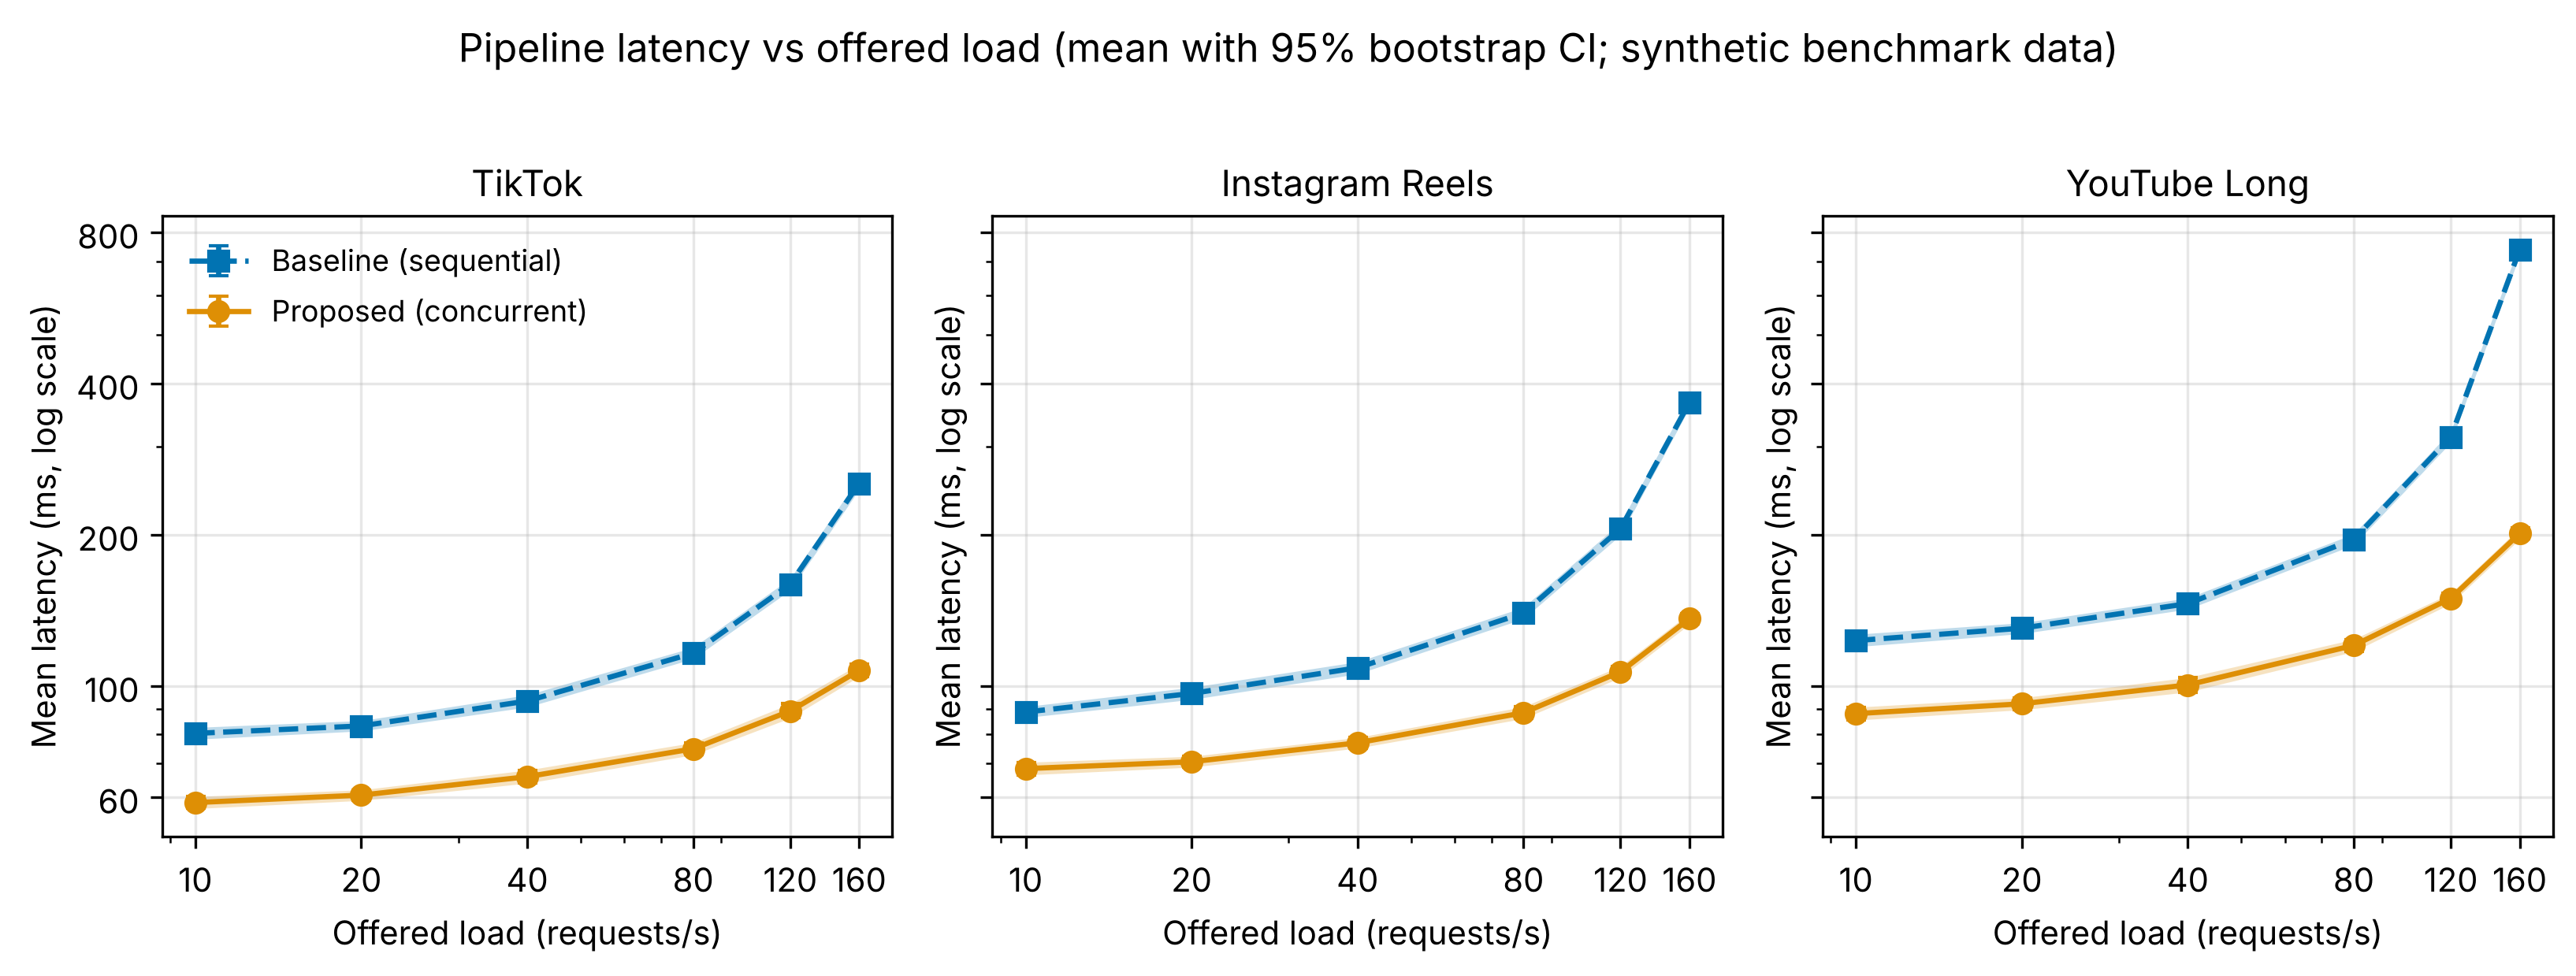

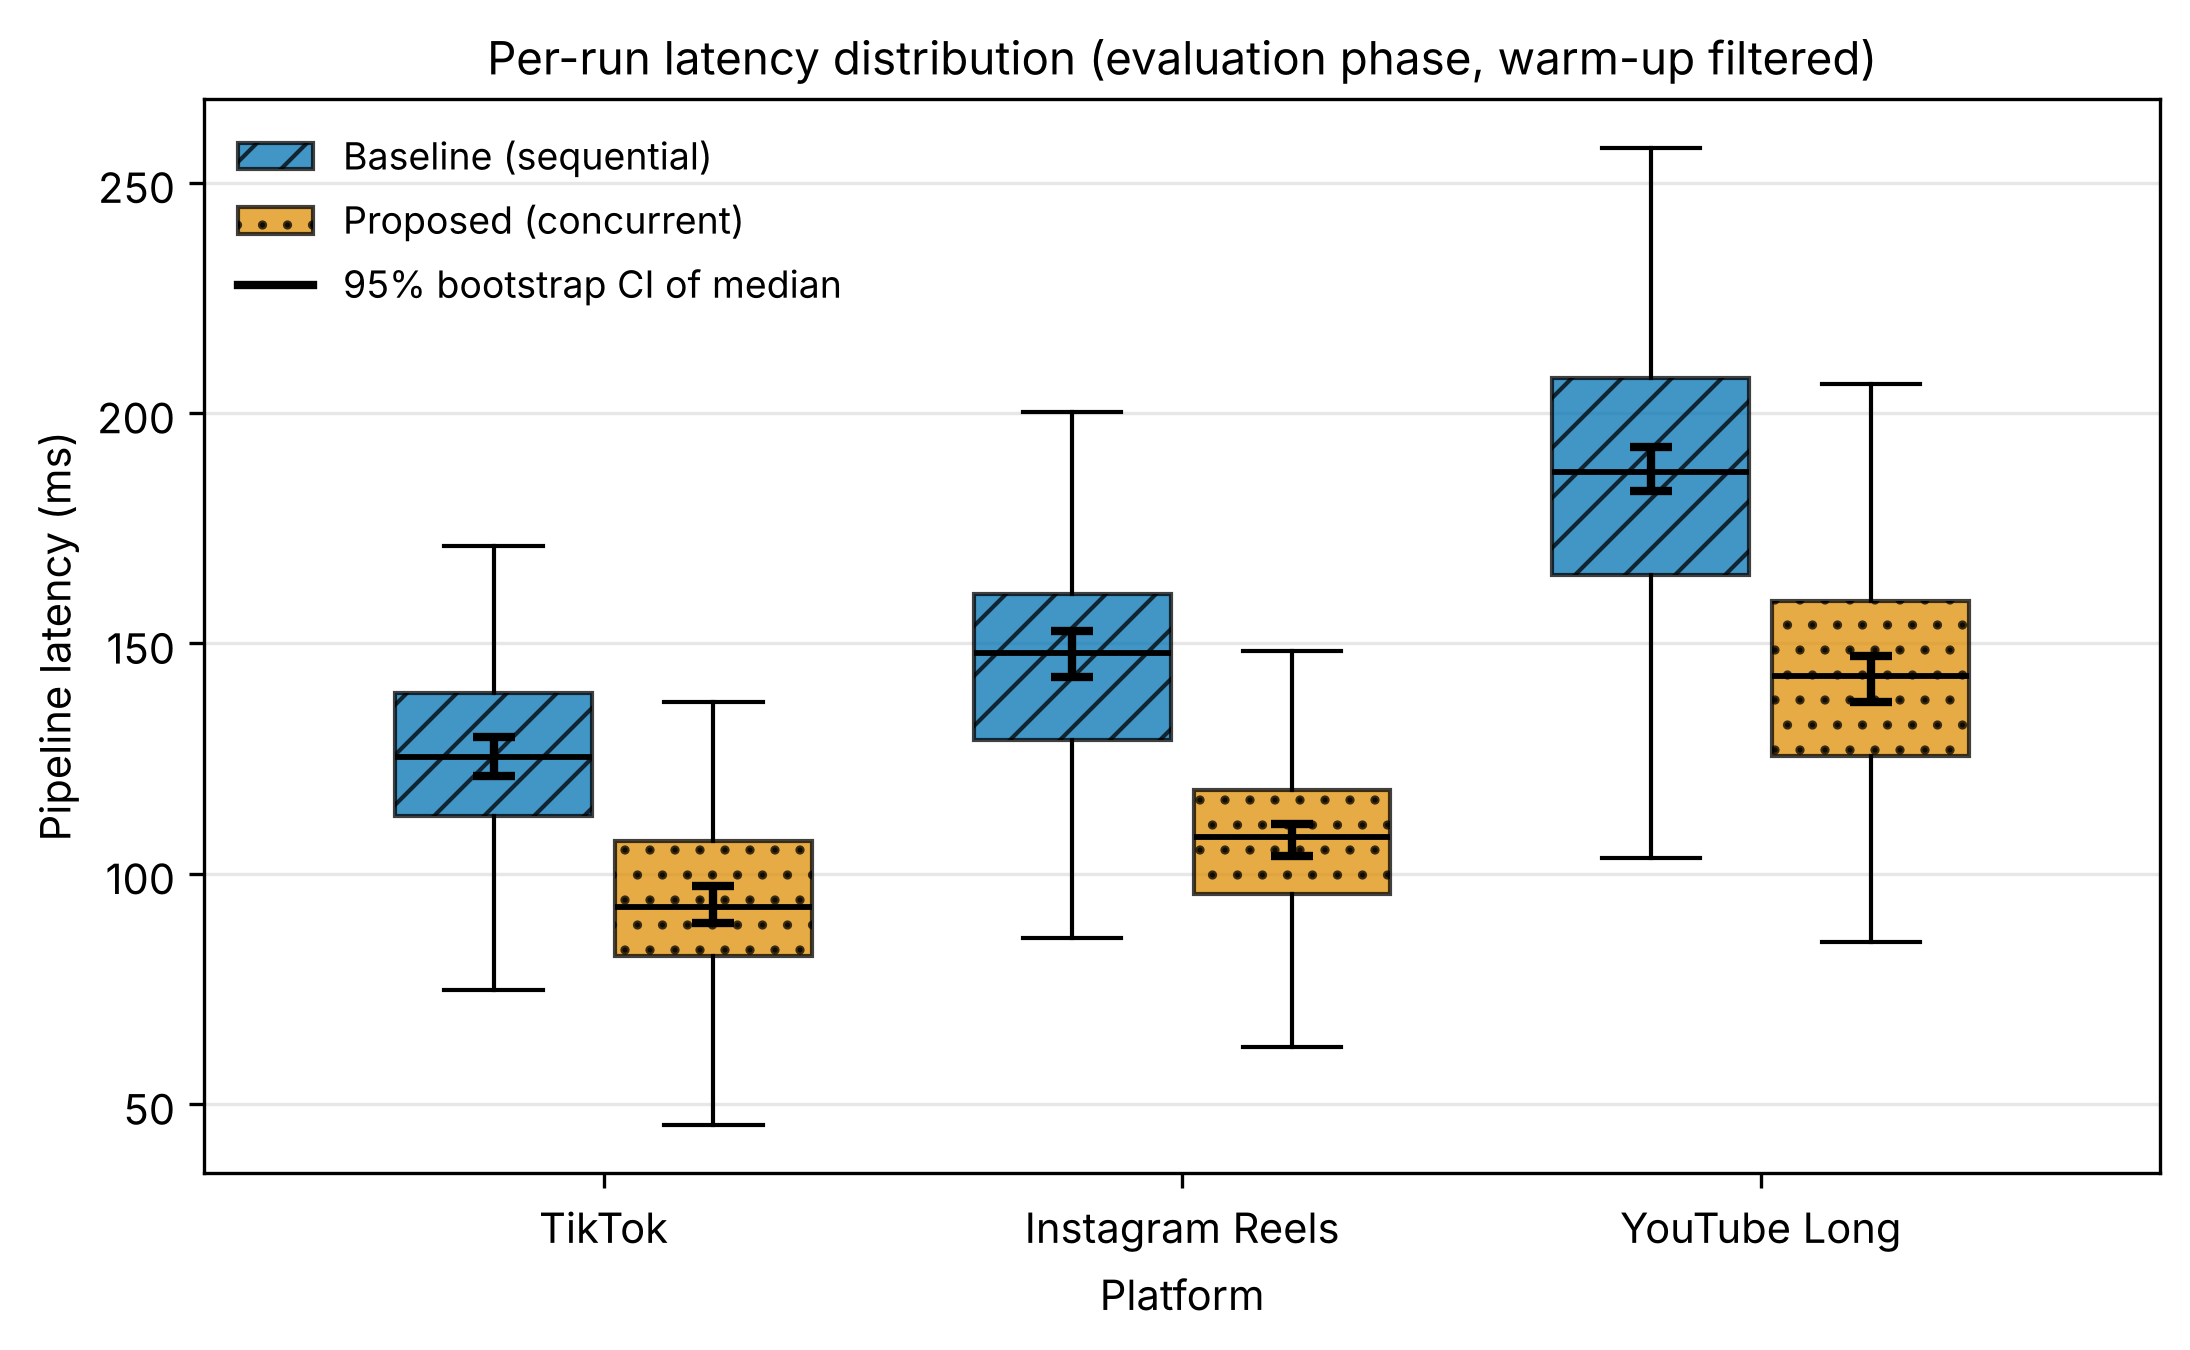

In [10]:
display(Image(filename=str(FIG_DIR / "fig1_latency_vs_load.png"), width=900))
display(Image(filename=str(FIG_DIR / "fig2_distribution_boxplot.png"), width=640))

## 8. Reproducibility check & conclusions

Re-running the aggregation from scratch must give exactly the saved CSV (seeded bootstrap).

In [11]:
again = summarize(filter_warmup(load_jsonl(RAW_PATH)))
saved = pd.read_csv(OUT_PATH)
same = np.allclose(again.select_dtypes("number").to_numpy(), saved.select_dtypes("number").to_numpy())
print(f"Re-computed summary identical to saved CSV: {same}")
assert same

Re-computed summary identical to saved CSV: True


**Conclusions (on the synthetic benchmark).**

- Warm-up runs are ~3× slower than steady state and are removed before every statistic.
- The Proposed (concurrent) collector reduces the median latency by roughly 24–27% on every platform, and the
  95% bootstrap CI of the reduction excludes 0 in all three cases.
- The gap widens with offered load: the Baseline latency explodes near saturation (log scale in fig. 1) while the
  Proposed collector degrades gracefully.
- The error rate stays below the 5% guardrail in every group.

**Limitation.** The logs are simulated, so these results show that the analysis pipeline works, not how real
TikTok / Instagram / YouTube collection behaves.